# Entrenamiento de la política PPO compartida

Tesis: Framework de selección inteligente de datos para el entrenamiento eficiente de modelos de lenguaje mediante aprendizaje por refuerzo y estimación del consumo energético. (Fase 2)

## Propósito

Utiliza únicamente los artefactos validados de la fase 1 (pipeline de características), entrena una única política PPO compartida para IMDb, AG News y TREC, y guarda todos los resultados en Google Drive.

Flujo experimental:

descriptor 18D → PPO → acción 5D → selección + truncado → DistilBERT → Validation + CodeCarbon → reward

## 1. Reproducibilidad y guardado
Se implementaron dos mecanismos complementarios:

1. Reproducibilidad del entrenamiento: semillas fijas para Python, NumPy, PyTorch, PPO, DataLoader, orden de episodios y selección. Se desactivan fuentes conocidas de aleatoriedad de CUDA cuando están disponibles y PPO se entrena en CPU, donde no aporta costo material frente al entrenamiento de DistilBERT.

2. Guardado de resultados: cada baseline y cada episodio guarda sus resultados, el estado de la política y, en cada checkpoint, los estados de los generadores aleatorios. Al volver a ejecutar el notebook, primero se buscan resultados ya completados y no se vuelve a medir energía ni a reentrenar episodios que ya quedaron consolidados.

In [ ]:
!pip -q install \
    "stable-baselines3==2.9.0" \
    "gymnasium==1.3.0" \
    "codecarbon==3.3.1" \
    "transformers==5.16.1" \
    "datasets==4.8.5" \
    "pandas==2.2.3" \
    "numpy==2.1.3" \
    "scikit-learn==1.9.1" \
    pyarrow

In [ ]:
from google.colab import drive

drive.mount('/content/drive', force_remount=False)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from __future__ import annotations

from datetime import datetime
import gc
import hashlib
import importlib.metadata as md
import json
import math
import os
import pickle
import random
import shutil
import time
import warnings
import zipfile
from pathlib import Path
from typing import Dict, List, Tuple, Optional, Any

os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import numpy as np
import pandas as pd
import torch
from sklearn.metrics import accuracy_score, f1_score

import gymnasium as gym
from gymnasium import spaces

from stable_baselines3 import PPO
from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3.common.vec_env import DummyVecEnv

from codecarbon import EmissionsTracker
from transformers import AutoModelForSequenceClassification, AutoTokenizer

warnings.filterwarnings("ignore")

EXPERIMENT_NAME = "ppo_shared_final_v2"

SEED = 42
TARGET_MODEL_NAME = "distilbert/distilbert-base-uncased"
DATASETS = ["imdb", "ag_news", "trec"]
DATASET_INFO = {
    "imdb": {"num_classes": 2},
    "ag_news": {"num_classes": 4},
    "trec": {"num_classes": 6},
}

N_TRAIN = 800
N_VAL = 300
MAX_TOKEN_CAP = 256
MIN_TOKEN_CAP = 8

REWARD_SEEDS = [11, 22, 33]
FINAL_EPISODES = 600
EPISODES_PER_DATASET = FINAL_EPISODES // len(DATASETS)
CHECKPOINT_EVERY_EPISODES = 12

BATCH_SIZE = 16
TRAIN_EPOCHS = 1
LEARNING_RATE = 5e-5
WEIGHT_DECAY = 0.0

CODECARBON_MEASURE_POWER_SECS = 1
PERFORMANCE_FLOOR = 0.95
PERFORMANCE_FLOOR_PENALTY = 2.0
ALPHA_PERFORMANCE = 0.5

# PPO se mantiene en CPU para reducir variación entre GPUs de Colab.
PPO_DEVICE = "cpu"

DRIVE_ROOT = Path("/content/drive/MyDrive/idsf-eft/framework")
ARTIFACT_ROOT = DRIVE_ROOT / "artifacts"
OUTPUT_ROOT = DRIVE_ROOT / "ppo_training"
RUN_ROOT = OUTPUT_ROOT / EXPERIMENT_NAME
MODEL_ROOT = RUN_ROOT / "models"
CHECKPOINT_ROOT = RUN_ROOT / "checkpoints"
RUNS_ROOT = RUN_ROOT / "training_runs"
RECORDS_ROOT = RUN_ROOT / "episode_records"
CODECARBON_ROOT = RUN_ROOT / "codecarbon"
ARCHIVE_ROOT = RUN_ROOT / "archives"

for path in [RUN_ROOT, MODEL_ROOT, CHECKPOINT_ROOT, RUNS_ROOT, RECORDS_ROOT, CODECARBON_ROOT, ARCHIVE_ROOT]:
    path.mkdir(parents=True, exist_ok=True)

print("Experiment:", EXPERIMENT_NAME)
print("Artifact root:", ARTIFACT_ROOT)
print("Run root:", RUN_ROOT)
print("PPO device:", PPO_DEVICE)

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=

Experiment: ppo_shared_final_v2
Artifact root: /content/drive/MyDrive/idsf-eft/framework/artifacts
Run root: /content/drive/MyDrive/idsf-eft/framework/ppo_training/ppo_shared_final_v2
PPO device: cpu


In [ ]:
def set_global_seed(seed: int) -> None:
    """Fija las fuentes de aleatoriedad controlables por el experimento."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    # Se desactiva TF32 para evitar una fuente adicional de variación numérica.
    if hasattr(torch.backends, "cuda") and hasattr(torch.backends.cuda, "matmul"):
        torch.backends.cuda.matmul.allow_tf32 = False
    if hasattr(torch.backends, "cudnn"):
        torch.backends.cudnn.allow_tf32 = False
    try:
        torch.use_deterministic_algorithms(True, warn_only=True)
    except Exception:
        pass


def get_rng_state() -> Dict[str, Any]:
    state = {
        "python": random.getstate(),
        "numpy": np.random.get_state(),
        "torch_cpu": torch.get_rng_state(),
    }
    if torch.cuda.is_available():
        state["torch_cuda"] = torch.cuda.get_rng_state_all()
    return state


def set_rng_state(state: Dict[str, Any]) -> None:
    random.setstate(state["python"])
    np.random.set_state(state["numpy"])
    torch.set_rng_state(state["torch_cpu"])
    if torch.cuda.is_available() and "torch_cuda" in state:
        torch.cuda.set_rng_state_all(state["torch_cuda"])


def atomic_json_dump(payload: Dict[str, Any], path: Path) -> None:
    tmp = path.with_suffix(path.suffix + ".tmp")
    with open(tmp, "w", encoding="utf-8") as f:
        json.dump(payload, f, indent=2, ensure_ascii=False, default=str)
    os.replace(tmp, path)


def atomic_text_write(text: str, path: Path) -> None:
    tmp = path.with_suffix(path.suffix + ".tmp")
    tmp.write_text(text, encoding="utf-8")
    os.replace(tmp, path)


def sha256_file(path: Path, chunk_size: int = 1024 * 1024) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)
            if not chunk:
                break
            h.update(chunk)
    return h.hexdigest()


def file_hash_manifest(root: Path) -> Dict[str, str]:
    files = [p for p in root.rglob("*") if p.is_file()]
    return {str(p.relative_to(root)): sha256_file(p) for p in sorted(files)}


set_global_seed(SEED)

EXPECTED_VERSIONS = {
    "stable-baselines3": "2.9.0",
    "gymnasium": "1.3.0",
    "codecarbon": "3.3.1",
    "transformers": "5.16.1",
    "datasets": "4.8.5",
    "pandas": "2.2.3",
    "numpy": "2.1.3",
    "scikit-learn": "1.9.1",
}

VERSIONS = {}
for package in list(EXPECTED_VERSIONS) + ["torch", "pyarrow"]:
    try:
        VERSIONS[package] = md.version(package)
    except md.PackageNotFoundError:
        VERSIONS[package] = "NO INSTALADO"

version_df = pd.DataFrame([{"package": k, "version": v} for k, v in VERSIONS.items()])
display(version_df)

for package, expected in EXPECTED_VERSIONS.items():
    actual = VERSIONS.get(package)
    if actual != expected:
        raise RuntimeError(
            f"Versión no reproducible para {package}: {actual}; se esperaba {expected}."
        )

if not VERSIONS["torch"].startswith("2.11.0"):
    raise RuntimeError(
        f"PyTorch actual={VERSIONS['torch']}. Para esta ejecución reproducible se requiere PyTorch 2.11.0.x."
    )

ENV_VERSIONS_PATH = RUN_ROOT / "environment_versions.json"
if ENV_VERSIONS_PATH.exists():
    atomic_json_dump(VERSIONS, RUN_ROOT / "environment_versions_last_check.json")
else:
    atomic_json_dump(VERSIONS, ENV_VERSIONS_PATH)
print("Entorno validado.")

,package,version
0,stable-baselines3,2.9.0
1,gymnasium,1.3.0
2,codecarbon,3.3.1
3,transformers,5.16.1
4,datasets,4.8.5
5,pandas,2.2.3
6,numpy,2.1.3
7,scikit-learn,1.9.1
8,torch,2.11.0+cu130
9,pyarrow,23.0.1


Entorno validado.


## 2. Cargar y validar los artefactos de la fase 1 (pipeline de características).

Se utilizan los parquet, descriptores y normalizadores ya generados por el pipeline multidataset.

También se calcula una huella SHA-256 de los artefactos de entrada para evitar mezclar accidentalmente una política entrenada con una versión distinta de los datos.

In [ ]:
required = [
    ARTIFACT_ROOT / "pipeline_metadata.json",
    ARTIFACT_ROOT / "descriptors" / "dataset_descriptors_18d.csv",
    ARTIFACT_ROOT / "descriptors" / "global_feature_scaler.json",
    ARTIFACT_ROOT / "features" / "selection_normalizers.json",
]
for d in DATASETS:
    required += [
        ARTIFACT_ROOT / "datasets" / f"{d}_train.parquet",
        ARTIFACT_ROOT / "datasets" / f"{d}_validation.parquet",
        ARTIFACT_ROOT / "features" / f"{d}_train800_features.parquet",
    ]

missing = [str(p) for p in required if not p.exists()]
if missing:
    raise FileNotFoundError("Faltan artefactos:\n" + "\n".join(missing))

ARTIFACT_HASHES = file_hash_manifest(ARTIFACT_ROOT)
ARTIFACT_SIGNATURE = hashlib.sha256(
    json.dumps(ARTIFACT_HASHES, sort_keys=True).encode("utf-8")
).hexdigest()

atomic_json_dump(ARTIFACT_HASHES, RUN_ROOT / "artifact_hashes.json")

with open(ARTIFACT_ROOT / "pipeline_metadata.json", "r", encoding="utf-8") as f:
    pipeline_metadata = json.load(f)

descriptor_df = pd.read_csv(
    ARTIFACT_ROOT / "descriptors" / "dataset_descriptors_18d.csv",
    index_col=0,
)

feature_tables: Dict[str, pd.DataFrame] = {}
split_tables: Dict[str, Dict[str, pd.DataFrame]] = {}

for dataset_name in DATASETS:
    feature_tables[dataset_name] = pd.read_parquet(
        ARTIFACT_ROOT / "features" / f"{dataset_name}_train800_features.parquet"
    )
    split_tables[dataset_name] = {
        "train": pd.read_parquet(
            ARTIFACT_ROOT / "datasets" / f"{dataset_name}_train.parquet"
        ),
        "validation": pd.read_parquet(
            ARTIFACT_ROOT / "datasets" / f"{dataset_name}_validation.parquet"
        ),
    }

assert descriptor_df.shape == (3, 18)
assert list(descriptor_df.index) == DATASETS
assert bool(((descriptor_df >= 0).all() & (descriptor_df <= 1).all()).all())

for d in DATASETS:
    train_df = split_tables[d]["train"]
    val_df = split_tables[d]["validation"]
    feat_df = feature_tables[d]

    assert len(train_df) == N_TRAIN
    assert len(val_df) == N_VAL
    assert feat_df["source_index"].nunique() == N_TRAIN
    assert feat_df["label"].nunique() == DATASET_INFO[d]["num_classes"]

print("Artifact signature:", ARTIFACT_SIGNATURE)
print("Artefactos y splits validados.")
display(descriptor_df.round(4))

Artifact signature: 8c4508a39bc386370f6c00f568e73ca0e2a99318ff4ab12d13afd448cd0621f1
Artefactos y splits validados.


,ppl_mean,ppl_std,ppl_p25,ppl_p75,length_mean,length_std,length_p25,length_p75,div_mean,div_std,div_p25,div_p75,num_classes_norm,class_entropy_norm,p_gt_32,p_gt_64,p_gt_128,p_gt_192
dataset,,,,,,,,,,,,,,,,,,
imdb,0.1815,0.1192,0.0926,0.2546,0.5418,0.2807,0.3205,0.7792,0.0938,0.1413,0.0118,0.1112,0.3333,0.3869,0.9975,0.9725,0.8550,0.5925
ag_news,0.3332,0.2117,0.1719,0.4794,0.0927,0.0303,0.0737,0.1084,0.3551,0.2232,0.1895,0.4634,0.6667,0.7737,0.9275,0.0975,0.0025,0.0000
trec,0.6060,0.2910,0.3914,0.8509,0.0097,0.0093,0.0022,0.0130,0.4956,0.2765,0.2687,0.6995,1.0000,0.9211,0.0012,0.0000,0.0000,0.0000


## 3. Firma del experimento

Se genera la firma combinando configuración experimental + versiones de software + huella de los artefactos. Si se intenta reanudar un experimento con entradas diferentes, el notebook se detiene en lugar de mezclar resultados.

In [ ]:
TORCH_SIGNATURE_LABEL = "2.11.0+cu128"

EXPERIMENT_CONFIG = {
    "experiment_name": EXPERIMENT_NAME,
    "seed": SEED,
    "target_model": TARGET_MODEL_NAME,
    "datasets": DATASETS,
    "n_train": N_TRAIN,
    "n_val": N_VAL,
    "max_token_cap": MAX_TOKEN_CAP,
    "min_token_cap": MIN_TOKEN_CAP,
    "reward_seeds": REWARD_SEEDS,
    "final_episodes": FINAL_EPISODES,
    "episodes_per_dataset": EPISODES_PER_DATASET,
    "checkpoint_every_episodes": CHECKPOINT_EVERY_EPISODES,
    "batch_size": BATCH_SIZE,
    "train_epochs": TRAIN_EPOCHS,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "codecarbon_measure_power_secs": CODECARBON_MEASURE_POWER_SECS,
    "performance_floor": PERFORMANCE_FLOOR,
    "performance_floor_penalty": PERFORMANCE_FLOOR_PENALTY,
    "alpha_performance": ALPHA_PERFORMANCE,
    "ppo_device": PPO_DEVICE,
    "versions": {**{k: VERSIONS[k] for k in EXPECTED_VERSIONS}, "torch": TORCH_SIGNATURE_LABEL},
    "artifact_signature": ARTIFACT_SIGNATURE,
}

EXPERIMENT_SIGNATURE = hashlib.sha256(
    json.dumps(EXPERIMENT_CONFIG, sort_keys=True, default=str).encode("utf-8")
).hexdigest()

existing_manifest = RUN_ROOT / "experiment_manifest.json"
if existing_manifest.exists():
    with open(existing_manifest, "r", encoding="utf-8") as f:
        previous_manifest = json.load(f)
    previous_sig = previous_manifest.get("experiment_signature")
    if previous_sig and previous_sig != EXPERIMENT_SIGNATURE:
        raise RuntimeError(
            "La carpeta del experimento existe pero su firma cambió. "
            "No se mezclan corridas. Para una réplica independiente se debe usar otro EXPERIMENT_NAME."
        )

atomic_json_dump(
    {
        "experiment_signature": EXPERIMENT_SIGNATURE,
        "config": EXPERIMENT_CONFIG,
        "status": "initialized",
        "created_or_checked_utc": datetime.utcnow().isoformat() + "Z",
    },
    existing_manifest,
)

print("Experiment signature:", EXPERIMENT_SIGNATURE)

Experiment signature: 0ac47a4596c06aebf5b90c499c6fde6c68caf52da12ab30e3937171c4f7a8d21


## 4. Tokenizer, modelo objetivo y estrategia de selección

La acción conceptual es: $a = [w_{ppl}, w_{len}, w_{div}, \rho, q]$ en $[0, 1]^5$


PPO trabaja internamente en $[-1, 1]^5$, por lo que se aplica la siguiente transformación:

$$a_j = \frac{u_j + 1}{2}, \quad \forall j \in \{1, 2, 3, 4, 5\}$$

Los tres primeros componentes se normalizan para formar los pesos de selección. $\rho$ determina la proporción retenida y $q$ determina el percentil de longitud usado como tope.

In [ ]:
target_tokenizer = AutoTokenizer.from_pretrained(TARGET_MODEL_NAME)

class DynamicTextCollator:
    def __init__(self, tokenizer, max_length: int):
        self.tokenizer = tokenizer
        self.max_length = int(max_length)

    def __call__(self, batch):
        texts = [x["text"] for x in batch]
        labels = torch.tensor([int(x["label"]) for x in batch], dtype=torch.long)

        encoded = self.tokenizer(
            texts,
            padding=True,
            truncation=True,
            max_length=self.max_length,
            return_tensors="pt",
        )
        encoded["labels"] = labels
        return encoded


def get_descriptor(dataset_name: str) -> np.ndarray:
    return descriptor_df.loc[dataset_name].to_numpy(dtype=np.float32)


def action_to_strategy(action: np.ndarray, feature_df: pd.DataFrame) -> Dict[str, float]:
    u = np.clip(np.asarray(action, dtype=np.float64), -1.0, 1.0)
    if u.shape != (5,):
        raise ValueError(f"La acción debe tener forma (5,), recibida {u.shape}.")

    a = (u + 1.0) / 2.0
    raw_weights = a[:3]
    denom = float(raw_weights.sum())
    weights = np.full(3, 1.0 / 3.0) if denom <= 1e-12 else raw_weights / denom

    rho = 0.2 + 0.8 * float(a[3])
    q = 0.5 + 0.5 * float(a[4])

    lengths = feature_df["true_length"].to_numpy(dtype=np.float64)
    q_length = float(np.quantile(lengths, q))
    max_length = int(np.clip(math.ceil(q_length), MIN_TOKEN_CAP, MAX_TOKEN_CAP))

    return {
        "u0_internal": float(u[0]), "u1_internal": float(u[1]), "u2_internal": float(u[2]),
        "u3_internal": float(u[3]), "u4_internal": float(u[4]),
        "a0_01": float(a[0]), "a1_01": float(a[1]), "a2_01": float(a[2]),
        "a3_01": float(a[3]), "a4_01": float(a[4]),
        "w_ppl": float(weights[0]), "w_len": float(weights[1]), "w_div": float(weights[2]),
        "rho": rho, "q": q, "max_length": max_length,
    }


def score_examples(feature_df: pd.DataFrame, strategy: Dict[str, float]) -> np.ndarray:
    return (
        strategy["w_ppl"] * feature_df["norm_log_perplexity"].to_numpy(float)
        + strategy["w_len"] * (1.0 - feature_df["norm_length"].to_numpy(float))
        + strategy["w_div"] * feature_df["norm_diversity"].to_numpy(float)
    )


def stratified_top_selection(
    feature_df: pd.DataFrame,
    score: np.ndarray,
    rho: float,
    seed: int,
) -> pd.DataFrame:
    df = feature_df.copy().reset_index(drop=True)
    df["_selection_score"] = np.asarray(score, dtype=np.float64)
    target_total = int(math.ceil(rho * len(df)))

    class_groups = {int(label): group for label, group in df.groupby("label", sort=True)}
    allocations: Dict[int, int] = {}
    residuals: Dict[int, float] = {}

    for label, group in class_groups.items():
        exact = rho * len(group)
        base = min(int(math.floor(exact)), len(group))
        allocations[label] = base
        residuals[label] = exact - base

    remaining = target_total - sum(allocations.values())
    for label in sorted(residuals, key=lambda x: (-residuals[x], x))[:max(0, remaining)]:
        allocations[label] = min(allocations[label] + 1, len(class_groups[label]))

    selected_parts = []
    for label, group in class_groups.items():
        n_select = allocations[label]
        if n_select <= 0:
            continue
        part = group.sort_values(
            ["_selection_score", "source_index"],
            ascending=[False, True],
        ).head(n_select)
        selected_parts.append(part)

    if not selected_parts:
        raise RuntimeError("La selección produjo cero ejemplos.")

    selected = pd.concat(selected_parts, ignore_index=True)
    selected = selected.sample(frac=1.0, random_state=int(seed) + 1).reset_index(drop=True)

    assert len(selected) == target_total
    assert set(selected["label"].unique()) == set(df["label"].unique())
    return selected


def apply_agent_action(feature_df: pd.DataFrame, action: np.ndarray, seed: int):
    strategy = action_to_strategy(action, feature_df)
    score = score_examples(feature_df, strategy)
    selected = stratified_top_selection(feature_df, score, strategy["rho"], seed)
    strategy["n_selected"] = int(len(selected))
    strategy["pdu"] = float(len(selected) / len(feature_df))
    return selected, strategy

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

## 5. Medición y caché de entrenamiento

La ventana energética cubre exclusivamente el entrenamiento de DistilBERT. La carga del modelo, la validación y otras operaciones quedan fuera de CodeCarbon.

Cada ejecución de DistilBERT tiene un `run_id` único y guarda un `result.json`. Si ese resultado ya existe, el notebook lo reutiliza y no se vuelve a entrenar ni a medir energía.

In [ ]:
def make_tracker(run_id: str):
    run_dir = CODECARBON_ROOT / run_id
    run_dir.mkdir(parents=True, exist_ok=True)

    tracker = EmissionsTracker(
        project_name="tesis_framework",
        experiment_id=run_id,
        measure_power_secs=CODECARBON_MEASURE_POWER_SECS,
        save_to_file=True,
        output_dir=str(run_dir),
        output_file="emissions.csv",
        save_to_api=False,
        log_level="error",
    )
    return tracker, run_dir / "emissions.csv"


def read_codecarbon_result(csv_path: Path) -> Dict[str, float]:
    if not csv_path.exists():
        raise FileNotFoundError(f"CodeCarbon no generó {csv_path}")

    cc = pd.read_csv(csv_path)
    if cc.empty:
        raise RuntimeError(f"CSV CodeCarbon vacío: {csv_path}")

    row = cc.iloc[-1]

    def val(name, default=np.nan):
        return float(row[name]) if name in cc.columns else float(default)

    return {
        "energy_kwh": val("energy_consumed"),
        "duration_s_codecarbon": val("duration"),
        "gpu_energy_kwh": val("gpu_energy"),
        "cpu_energy_kwh": val("cpu_energy"),
        "ram_energy_kwh": val("ram_energy"),
        "gpu_power_w": val("gpu_power"),
        "cpu_power_w": val("cpu_power"),
        "ram_power_w": val("ram_power"),
        "gpu_utilization_percent": val("gpu_utilization_percent"),
        "cpu_utilization_percent": val("cpu_utilization_percent"),
        "ram_used_gb": val("ram_used_gb"),
        "emissions_kg": val("emissions"),
    }

def training_signature_payload(
    dataset_name: str,
    seed: int,
    max_length: int,
    selected_source_indices: Optional[List[int]],
) -> Dict[str, Any]:
    return {
        "experiment_signature": EXPERIMENT_SIGNATURE,
        "dataset": dataset_name,
        "seed": int(seed),
        "max_length": int(max_length),
        "selected_source_indices_sha256": hashlib.sha256(
            json.dumps(selected_source_indices, sort_keys=True).encode("utf-8")
        ).hexdigest() if selected_source_indices is not None else None,
    }

def train_and_evaluate(
    train_df: pd.DataFrame,
    val_df: pd.DataFrame,
    num_classes: int,
    max_length: int,
    seed: int,
    run_id: str,
    selected_source_indices: Optional[List[int]] = None,
) -> Dict[str, float]:
    run_dir = RUNS_ROOT / run_id
    result_path = run_dir / "result.json"
    meta_path = run_dir / "run_meta.json"
    run_dir.mkdir(parents=True, exist_ok=True)

    signature_payload = training_signature_payload(
        dataset_name=str(train_df.iloc[0]["dataset"]) if "dataset" in train_df.columns else run_id,
        seed=seed,
        max_length=max_length,
        selected_source_indices=selected_source_indices,
    )
    signature = hashlib.sha256(
        json.dumps(signature_payload, sort_keys=True, default=str).encode("utf-8")
    ).hexdigest()

    if result_path.exists() and meta_path.exists():
        with open(meta_path, "r", encoding="utf-8") as f:
            cached_meta = json.load(f)
        if cached_meta.get("training_signature") != signature:
            raise RuntimeError(f"Cache inconsistente para {run_id}.")
        with open(result_path, "r", encoding="utf-8") as f:
            cached_result = json.load(f)
        return {k: float(v) for k, v in cached_result.items()}

    set_global_seed(seed)
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    model = AutoModelForSequenceClassification.from_pretrained(
        TARGET_MODEL_NAME,
        num_labels=num_classes,
    )
    model.to(torch.device("cuda" if torch.cuda.is_available() else "cpu"))

    device = next(model.parameters()).device
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
    )

    train_items = train_df[["text", "label"]].to_dict("records")
    val_items = val_df[["text", "label"]].to_dict("records")

    train_loader = torch.utils.data.DataLoader(
        train_items,
        batch_size=BATCH_SIZE,
        shuffle=True,
        collate_fn=DynamicTextCollator(target_tokenizer, max_length),
        generator=torch.Generator().manual_seed(seed),
        num_workers=0,
    )
    val_loader = torch.utils.data.DataLoader(
        val_items,
        batch_size=BATCH_SIZE,
        shuffle=False,
        collate_fn=DynamicTextCollator(target_tokenizer, max_length),
        num_workers=0,
    )

    tracker, cc_csv = make_tracker(run_id)

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    time_start = time.perf_counter()
    tracker.start()

    try:
        model.train()
        for _ in range(TRAIN_EPOCHS):
            for batch in train_loader:
                batch = {k: v.to(device) for k, v in batch.items()}
                optimizer.zero_grad(set_to_none=True)
                loss = model(**batch).loss
                loss.backward()
                optimizer.step()

        if torch.cuda.is_available():
            torch.cuda.synchronize()
        training_time = time.perf_counter() - time_start
    finally:
        tracker.stop()

    model.eval()
    y_true, y_pred = [], []
    with torch.inference_mode():
        for batch in val_loader:
            labels = batch.pop("labels")
            batch = {k: v.to(device) for k, v in batch.items()}
            logits = model(**batch).logits
            preds = torch.argmax(logits, dim=-1).cpu().numpy()
            y_true.extend(labels.numpy().tolist())
            y_pred.extend(preds.tolist())

    result = {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "training_time_s": float(training_time),
        **read_codecarbon_result(cc_csv),
    }

    if not np.isfinite(result["energy_kwh"]) or result["energy_kwh"] <= 0:
        raise RuntimeError(f"Energía inválida en {run_id}: {result['energy_kwh']}")

    atomic_json_dump(result, result_path)
    atomic_json_dump(
        {
            "training_signature": signature,
            "signature_payload": signature_payload,
            "run_id": run_id,
        },
        meta_path,
    )

    del model, optimizer, train_loader, val_loader
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result

## 6. Baseline Full para calibrar el reward

Se conserva el emparejamiento por semilla y se define el set de metricas:

* $A_{Full, D, s}$ → Accuracy
* $F1_{Full, D, s}$ → F1-Score
* $E_{Full, D, s}$ → Efficiency

para cada dataset ($D$) en {IMDb,AG News,TREC} y semilla ($s$) en {11,22,33}.

Cuando ya existe el `baseline_full_runs.csv` validado de una ejecución previa del mismo protocolo, se reutiliza. De lo contrario, se calculan los 9 entrenamientos y quedan guardados en Google Drive.

In [ ]:
def valid_full_baseline(df: pd.DataFrame) -> bool:
    expected = {(d, s) for d in DATASETS for s in REWARD_SEEDS}
    if len(df) != 9:
        return False
    if not {"dataset", "condition", "seed", "accuracy", "macro_f1", "energy_kwh", "training_time_s"}.issubset(df.columns):
        return False
    observed = {(str(r.dataset), int(r.seed)) for _, r in df.iterrows()}
    if observed != expected:
        return False
    if not (df["condition"] == "Full").all():
        return False
    if not np.isfinite(df["energy_kwh"]).all() or not (df["energy_kwh"] > 0).all():
        return False
    return True

def load_legacy_full_baseline() -> Optional[pd.DataFrame]:
    candidates = [
        OUTPUT_ROOT / "baseline_full_runs.csv",
        RUN_ROOT / "baseline_full_runs.csv",
    ]
    for candidate in candidates:
        if candidate.exists():
            df = pd.read_csv(candidate)
            if valid_full_baseline(df):
                return df
    return None

legacy_full = load_legacy_full_baseline()

if legacy_full is not None:
    baseline_full_df = legacy_full.copy()
    baseline_full_df["source"] = "cached_previous_notebook2"
    baseline_full_df.to_csv(RUN_ROOT / "baseline_full_runs.csv", index=False)
    print("Se reutilizó el baseline Full ya validado.")
else:
    baseline_rows = []
    for dataset_name in DATASETS:
        print(f"\n===== FULL BASELINE {dataset_name.upper()} =====")
        train_df = split_tables[dataset_name]["train"].copy()
        val_df = split_tables[dataset_name]["validation"]
        train_df["dataset"] = dataset_name

        for seed in REWARD_SEEDS:
            run_id = f"baseline_full_{dataset_name}_seed{seed}"
            result = train_and_evaluate(
                train_df=train_df,
                val_df=val_df,
                num_classes=DATASET_INFO[dataset_name]["num_classes"],
                max_length=MAX_TOKEN_CAP,
                seed=seed,
                run_id=run_id,
                selected_source_indices=None,
            )
            baseline_rows.append({
                "dataset": dataset_name,
                "condition": "Full",
                "seed": seed,
                "n_selected": N_TRAIN,
                "pdu": 1.0,
                "max_length": MAX_TOKEN_CAP,
                **result,
                "source": "computed_final_notebook2",
            })

    baseline_full_df = pd.DataFrame(baseline_rows)
    assert valid_full_baseline(baseline_full_df)
    baseline_full_df.to_csv(RUN_ROOT / "baseline_full_runs.csv", index=False)

reference_rows = []
full_reference: Dict[str, Dict[str, Dict[str, float]]] = {}
for dataset_name, group in baseline_full_df.groupby("dataset"):
    full_reference[dataset_name] = {}
    for _, row in group.iterrows():
        seed_key = str(int(row["seed"]))
        full_reference[dataset_name][seed_key] = {
            "full_accuracy": float(row["accuracy"]),
            "full_macro_f1": float(row["macro_f1"]),
            "full_energy_kwh": float(row["energy_kwh"]),
        }
        reference_rows.append({"dataset": dataset_name, "seed": int(row["seed"]), **full_reference[dataset_name][seed_key]})

reference_df = pd.DataFrame(reference_rows).sort_values(["dataset", "seed"]).reset_index(drop=True)
reference_df.to_csv(RUN_ROOT / "full_reward_references_by_seed.csv", index=False)
atomic_json_dump(full_reference, RUN_ROOT / "full_reward_references_by_seed.json")

print("Baseline Full listo.")
display(baseline_full_df.sort_values(["dataset", "seed"]).round(6))

Se reutilizó el baseline Full ya validado.
Baseline Full listo.


,dataset,condition,seed,n_selected,pdu,max_length,accuracy,macro_f1,training_time_s,energy_kwh,...,cpu_energy_kwh,ram_energy_kwh,gpu_power_w,cpu_power_w,ram_power_w,gpu_utilization_percent,cpu_utilization_percent,ram_used_gb,emissions_kg,source
3,ag_news,Full,11,800,1.0,256,0.900000,0.900105,5.912847,0.000132,...,0.000008,0.000016,56.920704,4.827633,10.0,98.000000,0.0,3.714163,0.000062,cached_previous_notebook2
4,ag_news,Full,22,800,1.0,256,0.903333,0.903264,5.992315,0.000135,...,0.000008,0.000016,57.738161,4.096248,10.0,98.000000,0.0,3.718456,0.000063,cached_previous_notebook2
5,ag_news,Full,33,800,1.0,256,0.896667,0.896164,6.034797,0.000133,...,0.000006,0.000017,57.274813,3.107300,10.0,98.833333,0.0,3.720155,0.000063,cached_previous_notebook2
0,imdb,Full,11,800,1.0,256,0.806667,0.803167,17.981383,0.000371,...,0.000023,0.000046,64.752290,4.702545,10.0,93.875000,0.0,3.717098,0.000175,cached_previous_notebook2
1,imdb,Full,22,800,1.0,256,0.846667,0.846667,16.105023,0.000363,...,0.000018,0.000044,66.505634,3.906960,10.0,99.375000,0.0,3.736365,0.000171,cached_previous_notebook2
2,imdb,Full,33,800,1.0,256,0.816667,0.812821,16.689501,0.000383,...,0.000028,0.000046,63.697213,5.684878,10.0,99.812500,0.0,3.727352,0.000180,cached_previous_notebook2
6,trec,Full,11,800,1.0,256,0.886667,0.748011,2.692648,0.000061,...,0.000005,0.000007,48.979161,5.433523,10.0,96.000000,0.0,3.769032,0.000029,cached_previous_notebook2
7,trec,Full,22,800,1.0,256,0.786667,0.668427,2.572755,0.000056,...,0.000002,0.000007,49.398200,2.566029,10.0,97.500000,0.0,3.772797,0.000026,cached_previous_notebook2
8,trec,Full,33,800,1.0,256,0.856667,0.729285,2.601821,0.000059,...,0.000003,0.000007,51.353809,3.236575,10.0,98.000000,0.0,3.775608,0.000028,cached_previous_notebook2


## 7. Diseño del reward ($R$)

Para cada episodio y su semilla de calibración se define:

1. Rendimiento relativo ($P_{D,s}$):

$$P_{D,s} = \frac{1}{2} \left( \frac{A_{D,s}}{A_{Full, D, s}} + \frac{F1_{D,s}}{F1_{Full, D, s}} \right)$$

>Promedio de la retención de exactitud y macro $F1$


2. Ahorro / Reducción de costo ($S_{D,s}$):

$$S_{D,s} = 1 - \frac{E_{D,s}}{E_{Full, D, s}}$$

>Proporción de eficiencia o recursos ahorrados

3. Reward base ($R_{base}$):

$$R_{base} = 0.5 \left( P_{D,s} - 1 \right) + 0.5 S_{D,s}$$

>Balancea en partes iguales la penalización por pérdida de rendimiento y la ganancia por eficiencia


4. Reward con penalización por umbral crítico ($R_{raw}$):

$$R_{raw} = R_{base} - 2 \max \big(0, \; 0.95 - P_{D,s}\big)$$

>Aplica una penalización lineal con factor $2$ si el rendimiento cae por debajo del $95\%$ respecto al baseline ($P_{D,s} < 0.95$)

Finalmente, ($R$) se proyecta sobre el intervalo $[-1,1]$ mediante la función de recorte:

$$R = \text{clip}(R_{raw}, -1, 1) = \max\Big(-1, \, \min\big(1, \, R_{raw}\big)\Big)$$

In [ ]:
def compute_reward(
    dataset_name: str,
    seed: int,
    accuracy: float,
    macro_f1: float,
    energy_kwh: float,
) -> Tuple[float, Dict[str, float]]:
    ref = full_reference[dataset_name][str(int(seed))]

    acc_ratio = accuracy / max(ref["full_accuracy"], 1e-8)
    f1_ratio = macro_f1 / max(ref["full_macro_f1"], 1e-8)
    performance_ratio = 0.5 * (acc_ratio + f1_ratio)

    energy_saving = 1.0 - energy_kwh / max(ref["full_energy_kwh"], 1e-12)

    base_reward = (
        ALPHA_PERFORMANCE * (performance_ratio - 1.0)
        + (1.0 - ALPHA_PERFORMANCE) * energy_saving
    )
    performance_penalty = PERFORMANCE_FLOOR_PENALTY * max(
        0.0, PERFORMANCE_FLOOR - performance_ratio
    )
    reward_raw = base_reward - performance_penalty
    reward = float(np.clip(reward_raw, -1.0, 1.0))

    return reward, {
        "acc_ratio": float(acc_ratio),
        "f1_ratio": float(f1_ratio),
        "performance_ratio": float(performance_ratio),
        "energy_saving": float(energy_saving),
        "base_reward": float(base_reward),
        "performance_penalty": float(performance_penalty),
        "reward_raw": float(reward_raw),
        "reward": reward,
    }

## 8. Plan balanceado de 600 episodios

Cada bloque contiene los tres datasets en orden aleatorio, pero reproducible. Por construcción:

- IMDb: 200 episodios.
- AG News: 200 episodios.
- TREC: 200 episodios.

El plan completo se guarda en Drive y se vuelve a cargar exactamente igual al reanudar.

In [ ]:
def make_balanced_episode_plan(n_episodes: int, seed: int) -> List[str]:
    if n_episodes % len(DATASETS) != 0:
        raise ValueError("El número de episodios debe ser múltiplo de 3.")

    rng = np.random.default_rng(seed)
    plan: List[str] = []
    for _ in range(n_episodes // len(DATASETS)):
        block = DATASETS.copy()
        rng.shuffle(block)
        plan.extend(block)

    counts = pd.Series(plan).value_counts().to_dict()
    expected = {d: n_episodes // len(DATASETS) for d in DATASETS}
    assert counts == expected
    return plan


EPISODE_PLAN_PATH = RUN_ROOT / "episode_plan_600.json"

if EPISODE_PLAN_PATH.exists():
    with open(EPISODE_PLAN_PATH, "r", encoding="utf-8") as f:
        raw_plan = json.load(f)
    if isinstance(raw_plan, dict) and "episodes" in raw_plan:
        episode_plan = list(raw_plan["episodes"])
    else:
        episode_plan = list(raw_plan)
else:
    episode_plan = make_balanced_episode_plan(FINAL_EPISODES, seed=2027)
    atomic_json_dump({"seed": 2027, "episodes": episode_plan}, EPISODE_PLAN_PATH)

if len(episode_plan) != FINAL_EPISODES:
    raise RuntimeError(f"El plan guardado no tiene {FINAL_EPISODES} episodios. Encontrados: {len(episode_plan)}")

assert pd.Series(episode_plan).value_counts().to_dict() == {
    d: EPISODES_PER_DATASET for d in DATASETS
}
print("Conteo:", pd.Series(episode_plan).value_counts().to_dict())
print("Primer bloque:", episode_plan[:3])

Conteo: {'ag_news': 200, 'trec': 200, 'imdb': 200}
Primer bloque: ['ag_news', 'trec', 'imdb']


## 9. Entorno Gymnasium

Cada episodio tiene horizonte 1: recibe el descriptor de un dataset, produce una acción, ejecuta selección + truncado + entrenamiento de DistilBERT, calcula la recompensa y termina.

In [ ]:
class SharedPolicyEnvironment(gym.Env):
    metadata = {"render_modes": []}

    def __init__(self, episode_plan: List[str], start_episode: int = 0):
        super().__init__()
        self.episode_plan = list(episode_plan)
        self.episode_cursor = int(start_episode)
        self.current_dataset = None

        self.observation_space = spaces.Box(
            low=0.0, high=1.0, shape=(18,), dtype=np.float32
        )
        self.action_space = spaces.Box(
            low=-1.0, high=1.0, shape=(5,), dtype=np.float32
        )

    def set_cursor(self, episode: int) -> None:
        self.episode_cursor = int(episode)
        self.current_dataset = None

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)
        idx = self.episode_cursor % len(self.episode_plan)
        self.current_dataset = self.episode_plan[idx]
        return get_descriptor(self.current_dataset), {
            "dataset": self.current_dataset,
            "episode_index": int(self.episode_cursor),
        }

    def step(self, action):
        dataset_name = self.current_dataset
        episode_index = int(self.episode_cursor)
        train_df = split_tables[dataset_name]["train"].copy()
        val_df = split_tables[dataset_name]["validation"]
        feature_df = feature_tables[dataset_name]

        reward_seed = REWARD_SEEDS[episode_index % len(REWARD_SEEDS)]
        selected_df, strategy = apply_agent_action(feature_df, action, reward_seed)
        selected_source_indices = [int(x) for x in selected_df["source_index"].tolist()]

        train_df = train_df[train_df["source_index"].isin(selected_source_indices)].copy()
        train_df = train_df.sort_values("source_index").reset_index(drop=True)
        train_df["dataset"] = dataset_name

        selection_hash = hashlib.sha256(
            json.dumps(selected_source_indices, sort_keys=True).encode("utf-8")
        ).hexdigest()[:12]

        run_id = (
            f"ppo_ep{episode_index:04d}_{dataset_name}_seed{reward_seed}"
            f"_L{int(strategy['max_length']):03d}_sel{selection_hash}"
        )

        result = train_and_evaluate(
            train_df=train_df,
            val_df=val_df,
            num_classes=DATASET_INFO[dataset_name]["num_classes"],
            max_length=int(strategy["max_length"]),
            seed=reward_seed,
            run_id=run_id,
            selected_source_indices=selected_source_indices,
        )

        reward, reward_details = compute_reward(
            dataset_name,
            reward_seed,
            result["accuracy"],
            result["macro_f1"],
            result["energy_kwh"],
        )

        info = {
            "dataset": dataset_name,
            "episode_index": episode_index,
            "reward_seed": reward_seed,
            "action_0_internal": float(action[0]),
            "action_1_internal": float(action[1]),
            "action_2_internal": float(action[2]),
            "action_3_internal": float(action[3]),
            "action_4_internal": float(action[4]),
            **strategy,
            **result,
            **reward_details,
            "training_run_id": run_id,
            "selection_hash": selection_hash,
            "_selected_source_indices": selected_source_indices,
        }

        self.episode_cursor += 1
        next_dataset = self.episode_plan[self.episode_cursor % len(self.episode_plan)]

        return get_descriptor(next_dataset), reward, True, False, info


def make_vector_env(plan: List[str], start_episode: int = 0):
    def factory():
        return SharedPolicyEnvironment(plan, start_episode=start_episode)
    return DummyVecEnv([factory])

## 10. Configuración PPO y checkpoints

In [ ]:
PPO_KWARGS = {
    "learning_rate": 3e-4,
    "n_steps": 12,
    "batch_size": 12,
    "n_epochs": 10,
    "gamma": 1.0,
    "gae_lambda": 1.0,
    "clip_range": 0.2,
    "ent_coef": 0.01,
    "vf_coef": 0.5,
    "max_grad_norm": 0.5,
    "policy_kwargs": {
        "net_arch": {
            "pi": [64, 64],
            "vf": [64, 64],
        }
    },
    "verbose": 1,
    "device": PPO_DEVICE,
}

atomic_json_dump(
    {
        "algorithm": "PPO",
        "seed": SEED,
        "episodes": FINAL_EPISODES,
        "checkpoint_every_episodes": CHECKPOINT_EVERY_EPISODES,
        "config": PPO_KWARGS,
        "internal_action_space": [-1.0, 1.0],
        "conceptual_action_space": [0.0, 1.0],
    },
    RUN_ROOT / "ppo_config.json",
)

ACTIVE_CHECKPOINT_MANAGER = None


class CheckpointablePPO(PPO):
    def train(self) -> None:
        super().train()
        manager = ACTIVE_CHECKPOINT_MANAGER
        if manager is not None and self.num_timesteps > 0:
            manager.maybe_save(self, completed_episodes=int(self.num_timesteps))


def build_ppo_model(env, seed: int):
    return CheckpointablePPO(
        "MlpPolicy",
        env,
        seed=seed,
        **PPO_KWARGS,
    )

In [ ]:
class PersistentEpisodeStore:
    def __init__(self, history_path: Path, records_root: Path):
        self.history_path = history_path
        self.records_root = records_root
        self.records_root.mkdir(parents=True, exist_ok=True)
        self.rows: List[Dict[str, Any]] = []

        if self.history_path.exists():
            self.history = pd.read_csv(self.history_path)
        else:
            self.history = pd.DataFrame()

    def truncate_to(self, n_episodes: int) -> None:
        if self.history.empty or "episode_index" not in self.history.columns:
            return
        self.history = (
            self.history[self.history["episode_index"] < int(n_episodes)]
            .sort_values("episode_index")
            .drop_duplicates("episode_index", keep="last")
            .reset_index(drop=True)
        )
        self.history.to_csv(self.history_path, index=False)

    def append(self, info: Dict[str, Any], selected_indices: List[int]) -> None:
        row = {k: v for k, v in info.items() if not k.startswith("_")}
        self.rows.append(row)

        new_df = pd.DataFrame([row])
        if self.history.empty:
            self.history = new_df
        else:
            self.history = pd.concat([self.history, new_df], ignore_index=True)
            self.history = (
                self.history
                .drop_duplicates("episode_index", keep="last")
                .sort_values("episode_index")
                .reset_index(drop=True)
            )

        self.history.to_csv(self.history_path, index=False)

        episode_index = int(row["episode_index"])
        record = {
            "episode_index": episode_index,
            "dataset": row["dataset"],
            "reward_seed": int(row["reward_seed"]),
            "training_run_id": row["training_run_id"],
            "selection_hash": row["selection_hash"],
            "selected_source_indices": [int(x) for x in selected_indices],
        }
        atomic_json_dump(
            record,
            self.records_root / f"episode_{episode_index:04d}.json",
        )

    @property
    def completed_episodes(self) -> int:
        if self.history.empty:
            return 0
        return int(self.history["episode_index"].nunique())


class EpisodeInfoCallback(BaseCallback):
    def __init__(self, store: PersistentEpisodeStore, start_episode: int = 0):
        super().__init__()
        self.store = store
        self.start_episode = int(start_episode)

    def _on_step(self) -> bool:
        for info in self.locals.get("infos", []):
            if not info or "episode_index" not in info or "reward" not in info:
                continue
            selected_indices = info.get("_selected_source_indices", [])
            self.store.append(info, selected_indices)
        return True

In [ ]:
class CheckpointManager:
    def __init__(self, root: Path, store: PersistentEpisodeStore):
        self.root = root
        self.store = store
        self.next_checkpoint = CHECKPOINT_EVERY_EPISODES

    def _checkpoint_dir(self, completed_episodes: int) -> Path:
        return self.root / f"ep_{completed_episodes:04d}"

    def list_valid_checkpoints(self) -> List[Path]:
        valid = []
        for path in self.root.glob("ep_*"):
            try:
                completed = int(path.name.split("_")[-1])
            except ValueError:
                continue
            model_path = path / "ppo_shared.zip"
            rng_path = path / "rng_state.pkl"
            meta_path = path / "checkpoint_meta.json"
            if completed > 0 and model_path.exists() and rng_path.exists() and meta_path.exists():
                valid.append(path)
        return sorted(valid, key=lambda p: int(p.name.split("_")[-1]))

    def latest_checkpoint(self) -> Optional[Path]:
        checkpoints = self.list_valid_checkpoints()
        return checkpoints[-1] if checkpoints else None

    def maybe_save(self, model: CheckpointablePPO, completed_episodes: int) -> Optional[Path]:
        if completed_episodes < self.next_checkpoint:
            return None
        if completed_episodes % CHECKPOINT_EVERY_EPISODES != 0:
            return None

        final_dir = self._checkpoint_dir(completed_episodes)
        if (final_dir / "checkpoint_meta.json").exists():
            self.next_checkpoint = completed_episodes + CHECKPOINT_EVERY_EPISODES
            return final_dir

        tmp_dir = self.root / f".tmp_ep_{completed_episodes:04d}"
        if tmp_dir.exists():
            shutil.rmtree(tmp_dir)
        tmp_dir.mkdir(parents=True, exist_ok=True)

        model_tmp = tmp_dir / "ppo_shared"
        model.save(model_tmp)
        with open(tmp_dir / "rng_state.pkl", "wb") as f:
            pickle.dump(get_rng_state(), f, protocol=pickle.HIGHEST_PROTOCOL)

        meta = {
            "completed_episodes": int(completed_episodes),
            "next_episode": int(completed_episodes),
            "experiment_signature": EXPERIMENT_SIGNATURE,
            "history_rows": int(self.store.completed_episodes),
            "saved_utc": datetime.utcnow().isoformat() + "Z",
        }
        atomic_json_dump(meta, tmp_dir / "checkpoint_meta.json")

        if final_dir.exists():
            shutil.rmtree(final_dir)
        shutil.move(str(tmp_dir), str(final_dir))

        self.next_checkpoint = completed_episodes + CHECKPOINT_EVERY_EPISODES
        return final_dir

    @staticmethod
    def load_checkpoint(path: Path, env):
        with open(path / "checkpoint_meta.json", "r", encoding="utf-8") as f:
            meta = json.load(f)
        if meta.get("experiment_signature") != EXPERIMENT_SIGNATURE:
            raise RuntimeError("La firma del checkpoint no coincide con el experimento actual.")

        model = CheckpointablePPO.load(
            path / "ppo_shared.zip",
            env=env,
            device=PPO_DEVICE,
        )
        with open(path / "rng_state.pkl", "rb") as f:
            rng_state = pickle.load(f)
        set_rng_state(rng_state)
        return model, meta

## 11. Ejecución

Si el experimento está terminado: se carga `ppo_shared_final.zip` y `ppo_final_history.csv`, no se entrena nada otra vez.


In [ ]:
HISTORY_PATH = RUN_ROOT / "ppo_final_history.csv"
FINAL_MODEL_PATH = MODEL_ROOT / "ppo_shared_final.zip"
FINAL_MANIFEST_PATH = RUN_ROOT / "final_manifest.json"

store = PersistentEpisodeStore(HISTORY_PATH, RECORDS_ROOT)

# Determina si ya existe un resultado final completo.
final_complete = False
if FINAL_MANIFEST_PATH.exists() and FINAL_MODEL_PATH.exists() and HISTORY_PATH.exists():
    with open(FINAL_MANIFEST_PATH, "r", encoding="utf-8") as f:
        final_manifest = json.load(f)
    final_complete = (
        final_manifest.get("experiment_signature") == EXPERIMENT_SIGNATURE
        and int(final_manifest.get("completed_episodes", -1)) == FINAL_EPISODES
        and len(pd.read_csv(HISTORY_PATH)) == FINAL_EPISODES
    )

if final_complete:
    print("EXPERIMENTO COMPLETO: se cargarán los resultados guardados.")
else:
    checkpoint_manager = CheckpointManager(CHECKPOINT_ROOT, store)
    latest = checkpoint_manager.latest_checkpoint()

    if latest is not None:
        model, checkpoint_meta = checkpoint_manager.load_checkpoint(
            latest,
            env=make_vector_env(episode_plan, start_episode=0),
        )
        start_episode = int(checkpoint_meta["completed_episodes"])
        store.truncate_to(start_episode)
        model.get_env().close()
        resume_env = make_vector_env(episode_plan, start_episode=start_episode)
        resume_env.envs[0].set_cursor(start_episode)
        model.set_env(resume_env)

        checkpoint_manager.next_checkpoint = (
            start_episode + CHECKPOINT_EVERY_EPISODES
        )
        print(f"Reanudando desde checkpoint: {start_episode} episodios.")
    else:
        start_episode = 0
        env = make_vector_env(episode_plan, start_episode=0)
        env.envs[0].set_cursor(0)
        set_global_seed(SEED)
        model = build_ppo_model(env, seed=SEED)
        checkpoint_manager = CheckpointManager(CHECKPOINT_ROOT, store)
        print("No hay checkpoint válido: iniciando PPO desde cero.")

    if not final_complete:
        ACTIVE_CHECKPOINT_MANAGER = checkpoint_manager
        callback = EpisodeInfoCallback(store, start_episode=start_episode)
        remaining = FINAL_EPISODES - start_episode

        if remaining > 0:
            model.learn(
                total_timesteps=remaining,
                reset_num_timesteps=False,
                callback=callback,
                progress_bar=True,
            )

        model.save(MODEL_ROOT / "ppo_shared_final")

        history_now = pd.read_csv(HISTORY_PATH)
        if len(history_now) != FINAL_EPISODES:
            raise RuntimeError(
                f"Historial incompleto: {len(history_now)} de {FINAL_EPISODES} episodios."
            )

        atomic_json_dump(
            {
                "experiment_signature": EXPERIMENT_SIGNATURE,
                "completed_episodes": FINAL_EPISODES,
                "model_path": str(FINAL_MODEL_PATH),
                "history_path": str(HISTORY_PATH),
                "saved_utc": datetime.utcnow().isoformat() + "Z",
            },
            FINAL_MANIFEST_PATH,
        )
        ACTIVE_CHECKPOINT_MANAGER = None
        model.get_env().close()
        print("Entrenamiento definitivo completado.")

EXPERIMENTO COMPLETO: se cargarán los resultados guardados.


## 12. Cargar el resultado final y generar auditoría



In [ ]:
with open(FINAL_MANIFEST_PATH, "r", encoding="utf-8") as f:
    final_manifest = json.load(f)

final_history = pd.read_csv(HISTORY_PATH).sort_values("episode_index").reset_index(drop=True)

assert len(final_history) == FINAL_EPISODES
assert final_history["episode_index"].tolist() == list(range(FINAL_EPISODES))
assert set(final_history["dataset"].unique()) == set(DATASETS)
assert final_history["dataset"].value_counts().to_dict() == {
    d: EPISODES_PER_DATASET for d in DATASETS
}
assert np.isfinite(final_history["reward"]).all()
assert np.isfinite(final_history["energy_kwh"]).all()
assert (final_history["energy_kwh"] > 0).all()
assert (final_history["n_selected"] > 0).all()
assert ((final_history["rho"] >= 0.2) & (final_history["rho"] <= 1.0)).all()
assert ((final_history["q"] >= 0.5) & (final_history["q"] <= 1.0)).all()

summary = (
    final_history.groupby("dataset")
    .agg(
        episodes=("reward", "count"),
        reward_mean=("reward", "mean"),
        reward_std=("reward", "std"),
        rho_mean=("rho", "mean"),
        pdu_mean=("pdu", "mean"),
        max_length_mean=("max_length", "mean"),
        accuracy_mean=("accuracy", "mean"),
        macro_f1_mean=("macro_f1", "mean"),
        energy_kwh_mean=("energy_kwh", "mean"),
        training_time_s_mean=("training_time_s", "mean"),
        performance_ratio_mean=("performance_ratio", "mean"),
        energy_saving_mean=("energy_saving", "mean"),
    )
    .reset_index()
)

summary.to_csv(RUN_ROOT / "ppo_training_summary.csv", index=False)

actions_summary = (
    final_history.groupby("dataset")[[
        "action_0_internal", "action_1_internal", "action_2_internal",
        "action_3_internal", "action_4_internal",
    ]]
    .agg(["mean", "std"])
)
actions_summary.to_csv(RUN_ROOT / "ppo_action_summary.csv")

print("Resumen por dataset:")
display(summary.round(6))

print("Resumen de acciones:")
display(actions_summary.round(4))

Resumen por dataset:


,dataset,episodes,reward_mean,reward_std,rho_mean,pdu_mean,max_length_mean,accuracy_mean,macro_f1_mean,energy_kwh_mean,training_time_s_mean,performance_ratio_mean,energy_saving_mean
0,ag_news,200,0.229929,0.089081,0.569396,0.569912,80.080,0.855483,0.853613,0.000056,2.657281,0.949677,0.575949
1,imdb,200,0.128564,0.244331,0.507731,0.508188,240.175,0.792117,0.778094,0.000190,8.707379,0.956975,0.495747
2,trec,200,-0.060059,0.243701,0.655741,0.656275,12.545,0.754433,0.633939,0.000041,1.959070,0.891359,0.303867


Resumen de acciones:


action_0_internal         action_1_internal         action_2_internal  \
                     mean     std              mean     std              mean   
dataset                                                                         
ag_news           -0.2937  0.7040            0.4761  0.5993           -0.5330   
imdb              -0.4468  0.5986            0.2751  0.7642           -0.4172   
trec              -0.1745  0.6306            0.7055  0.5725           -0.5978   

                action_3_internal         action_4_internal          
            std              mean     std              mean     std  
dataset                                                              
ag_news  0.5617           -0.0765  0.6657           -0.3490  0.8432  
imdb     0.4706           -0.2307  0.6670           -0.5005  0.7164  
trec     0.5330            0.1394  0.5555           -0.6646  0.5779

In [ ]:
# Indicadores técnicos de integridad y exploración.
checks = {
    "600_episodes": len(final_history) == FINAL_EPISODES,
    "200_each_dataset": all(final_history["dataset"].value_counts().get(d, 0) == 200 for d in DATASETS),
    "finite_reward": bool(np.isfinite(final_history["reward"]).all()),
    "finite_energy": bool(np.isfinite(final_history["energy_kwh"]).all()),
    "positive_energy": bool((final_history["energy_kwh"] > 0).all()),
    "positive_selection": bool((final_history["n_selected"] > 0).all()),
    "rho_varies": bool(final_history["rho"].nunique() > 1),
    "q_varies": bool(final_history["q"].nunique() > 1),
    "max_length_in_bounds": bool(((final_history["max_length"] >= MIN_TOKEN_CAP) & (final_history["max_length"] <= MAX_TOKEN_CAP)).all()),
    "pdu_in_bounds": bool(((final_history["pdu"] > 0) & (final_history["pdu"] <= 1)).all()),
}

checks["all_technical_checks"] = all(checks.values())

print(json.dumps(checks, indent=2, ensure_ascii=False))
atomic_json_dump(checks, RUN_ROOT / "final_integrity_checks.json")

# Saturación de acciones:
saturation_rows = []
for d, group in final_history.groupby("dataset"):
    row = {"dataset": d}
    for action_col in [f"action_{i}_internal" for i in range(5)]:
        values = group[action_col].to_numpy(float)
        row[action_col + "_at_lower"] = float(np.mean(values <= -0.999))
        row[action_col + "_at_upper"] = float(np.mean(values >= 0.999))
        row[action_col + "_inside"] = float(np.mean((values > -0.999) & (values < 0.999)))
    saturation_rows.append(row)

saturation_df = pd.DataFrame(saturation_rows)
saturation_df.to_csv(RUN_ROOT / "ppo_action_saturation.csv", index=False)
display(saturation_df.round(4))


{
  "600_episodes": true,
  "200_each_dataset": true,
  "finite_reward": true,
  "finite_energy": true,
  "positive_energy": true,
  "positive_selection": true,
  "rho_varies": true,
  "q_varies": true,
  "max_length_in_bounds": true,
  "pdu_in_bounds": true,
  "all_technical_checks": true
}


,dataset,action_0_internal_at_lower,action_0_internal_at_upper,action_0_internal_inside,action_1_internal_at_lower,action_1_internal_at_upper,action_1_internal_inside,action_2_internal_at_lower,action_2_internal_at_upper,action_2_internal_inside,action_3_internal_at_lower,action_3_internal_at_upper,action_3_internal_inside,action_4_internal_at_lower,action_4_internal_at_upper,action_4_internal_inside
0,ag_news,0.230,0.045,0.725,0.025,0.415,0.56,0.48,0.01,0.51,0.010,0.175,0.815,0.515,0.205,0.280
1,imdb,0.240,0.010,0.750,0.125,0.355,0.52,0.18,0.00,0.82,0.220,0.045,0.735,0.405,0.105,0.490
2,trec,0.035,0.060,0.905,0.045,0.695,0.26,0.46,0.00,0.54,0.005,0.100,0.895,0.600,0.025,0.375


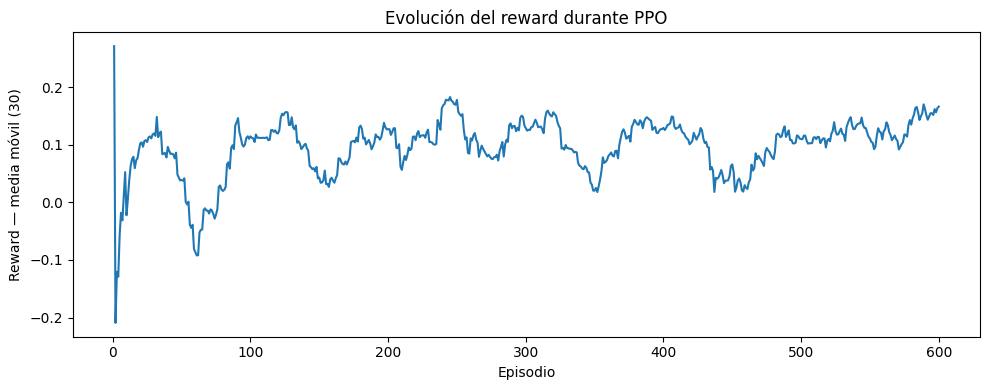

In [ ]:
# Tendencia de reward mediante media móvil de 30 episodios.
import matplotlib.pyplot as plt

rolling = final_history["reward"].rolling(30, min_periods=1).mean()
plt.figure(figsize=(10, 4))
plt.plot(final_history["episode_index"] + 1, rolling)
plt.xlabel("Episodio")
plt.ylabel("Reward — media móvil (30)")
plt.title("Evolución del reward durante PPO")
plt.tight_layout()
plt.show()

In [ ]:
# Huellas finales para auditoría de reproducibilidad.
final_model = CheckpointablePPO.load(FINAL_MODEL_PATH, device=PPO_DEVICE)

history_hash = sha256_file(HISTORY_PATH)
model_hash = sha256_file(FINAL_MODEL_PATH)
summary_hash = sha256_file(RUN_ROOT / "ppo_training_summary.csv")

repro_manifest = {
    "experiment_name": EXPERIMENT_NAME,
    "experiment_signature": EXPERIMENT_SIGNATURE,
    "artifact_signature": ARTIFACT_SIGNATURE,
    "completed_episodes": FINAL_EPISODES,
    "history_sha256": history_hash,
    "model_sha256": model_hash,
    "summary_sha256": summary_hash,
    "deterministic_settings": {
        "seed": SEED,
        "ppo_device": PPO_DEVICE,
        "cudnn_deterministic": True,
        "cudnn_benchmark": False,
        "tf32_disabled": True,
        "torch_deterministic_algorithms_warn_only": True,
        "results_reused_on_rerun": True,
    },
}
atomic_json_dump(repro_manifest, RUN_ROOT / "reproducibility_manifest.json")

# Actualiza el manifiesto principal sin sobrescribir la firma.
atomic_json_dump(
    {
        "experiment_signature": EXPERIMENT_SIGNATURE,
        "config": EXPERIMENT_CONFIG,
        "status": "completed",
        "completed_episodes": FINAL_EPISODES,
        "history_sha256": history_hash,
        "model_sha256": model_hash,
        "finished_utc": datetime.utcnow().isoformat() + "Z",
    },
    RUN_ROOT / "experiment_manifest.json",
)

print("History SHA-256:", history_hash)
print("Model SHA-256:", model_hash)
print("Reproducibility manifestado en:", RUN_ROOT / "reproducibility_manifest.json")

History SHA-256: 589d8600c8c40751f6c94b98edcdc990a27c4ea8374dee0138133e29d280c49a
Model SHA-256: 937eb0a768a23f649e58691ed3ba08dac9785857343546330378b04c0d781c28
Reproducibility manifestado en: /content/drive/MyDrive/idsf-eft/framework/ppo_training/ppo_shared_final_v2/reproducibility_manifest.json
